# Caracterización automática de la escoliosis mediante análisis geométrico
**16.63 Procesamiento de Señales e Imágenes Biomédicas — TPI 2026 Q2**
Grupo 6 · Martina Jacob (62649)

Este notebook estima el **ángulo de Cobb** en radiografías AP de columna completa (AASCE/MICCAI 2019, 98 imágenes) con técnicas clásicas de procesamiento de imágenes, **sin aprendizaje automático**, y clasifica la gravedad según Hong et al. (2017):

| Gravedad | Ángulo de Cobb |
|---|---|
| Inferior al umbral | < 10° |
| Leve | 10° ≤ Cobb < 25° |
| Moderada | 25° ≤ Cobb < 40° |
| Severa | ≥ 40° |

**Organización del código**

- `cobb_pipeline.py`: todas las etapas del procesamiento como funciones, la lectura de la referencia, el emparejamiento de curvas y las métricas.
- `visualizacion.py`: las figuras de cada etapa.
- Este notebook: recorre el pipeline paso a paso sobre una radiografía, ofrece una interfaz interactiva y evalúa las 98 imágenes.

Las anotaciones de referencia se usan **sólo para evaluar**; ninguna etapa del procesamiento automático las consulta.

## 1. Configuración

In [1]:
# En Colab: clonar el repositorio para disponer de los módulos.
import sys, os
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/martinajacob28/PSIB2026Q2-TPI-Jacob"

if EN_COLAB and not Path("cobb_pipeline.py").exists():
    import subprocess
    subprocess.run(["git", "clone", "-q", REPO_URL, "repo"], check=True)
    os.chdir("repo")

print("Directorio de trabajo:", Path.cwd())

Directorio de trabajo: /home/claude/work/exec


In [2]:
import zipfile
import urllib.request

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import cobb_pipeline as cp
import visualizacion as vis

pd.set_option("display.precision", 2)
plt.rcParams["figure.dpi"] = 90
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.5.3


## 2. Dataset

Se descarga el archivo con las 98 radiografías de prueba del desafío AASCE 2019. Si ya existe la carpeta `data/`, no se vuelve a descargar.
Las anotaciones (68 esquinas por imagen, en coordenadas de la imagen original) provienen del repositorio público `sudaoer/AASCE2019-test98-annotations`; si existe la carpeta `referencias/`, se leen de allí.

In [3]:
DATA_DIR = Path(os.environ.get("AASCE_DATA", "data"))
ZIP_PATH = Path("Archive.zip")
REF_DIR = Path("referencias")   # opcional: *_corner.pts locales

if not DATA_DIR.exists() or not any(DATA_DIR.rglob("*.jpg")):
    if not ZIP_PATH.exists():
        print("Descargando dataset…")
        urllib.request.urlretrieve(cp.URL_DATASET, ZIP_PATH)
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        if z.testzip() is not None:
            raise ValueError("ZIP dañado")
        for e in z.infolist():
            partes = Path(e.filename).parts
            if "__MACOSX" in partes or any(p.startswith("._") for p in partes):
                continue
            destino = (DATA_DIR / e.filename).resolve()
            if not destino.is_relative_to(DATA_DIR.resolve()):
                raise ValueError("Ruta fuera de la carpeta destino")
            z.extract(e, DATA_DIR)

imagenes = sorted(p for p in DATA_DIR.rglob("*")
                  if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
assert len(imagenes) == 98, f"Se esperaban 98 imágenes y hay {len(imagenes)}"
REF = REF_DIR if REF_DIR.exists() else None
print("Imágenes:", len(imagenes), "| Referencias locales:", REF is not None)

Imágenes: 98 | Referencias locales: True


### 2.1 Exploración: lectura y dimensiones

In [4]:
inventario = []
for ruta in imagenes:
    img = cv2.imread(str(ruta), cv2.IMREAD_GRAYSCALE)
    assert img is not None, ruta.name
    inventario.append({"archivo": ruta.name, "alto_px": img.shape[0],
                       "ancho_px": img.shape[1], "tipo": str(img.dtype)})
inventario = pd.DataFrame(inventario)
display(inventario.head())
display(inventario[["alto_px", "ancho_px"]].describe().round(0))

,archivo,alto_px,ancho_px,tipo
0,01-July-2019-1.jpg,6223,2057,uint8
1,01-July-2019-10.jpg,6841,2474,uint8
2,01-July-2019-11.jpg,6223,2201,uint8
3,01-July-2019-12.jpg,7316,2079,uint8
4,01-July-2019-13.jpg,6302,2201,uint8


,alto_px,ancho_px
count,98.0,98.0
mean,5268.0,1759.0
std,1963.0,653.0
min,985.0,273.0
25%,5506.0,1593.0
50%,6039.0,1841.0
75%,6384.0,2237.0
max,7316.0,2748.0


Las imágenes son de 8 bits en escala de grises y su tamaño varía mucho (de ≈ 1000 a ≈ 7300 px de alto). Por eso **todos los parámetros espaciales del pipeline se expresan como fracciones del alto o del ancho** y no en píxeles absolutos. Tampoco hay metadatos de espaciado, así que sólo se informan ángulos (independientes de la escala).

## 3. Pipeline paso a paso sobre una radiografía

Se elige una radiografía de ejemplo (`INDICE` entre 0 y 97).

In [5]:
INDICE = 0
ruta = imagenes[INDICE]
img = cv2.imread(str(ruta), cv2.IMREAD_GRAYSCALE)
r = cp.procesar_radiografia(img, con_cajas=True)
print(ruta.name, img.shape)

01-July-2019-1.jpg (6223, 2057)


### 3.1 Preprocesamiento exploratorio

Se comparan un filtro Gaussiano 5×5, CLAHE (`clipLimit=2.0`, `tileGridSize=(8, 8)`) y su combinación. El Gaussiano atenúa el ruido granular pero difumina bordes; CLAHE mejora el contraste local pero también realza costillas y ruido.

- `tileGridSize=(8, 8)` divide la imagen en 64 regiones; el contraste se ecualiza en cada una y se interpola entre ellas para evitar bordes de bloque. Indica la cantidad de regiones, no su tamaño.
- `clipLimit=2.0` recorta los histogramas locales para limitar la amplificación del ruido; no significa que el contraste se duplique.

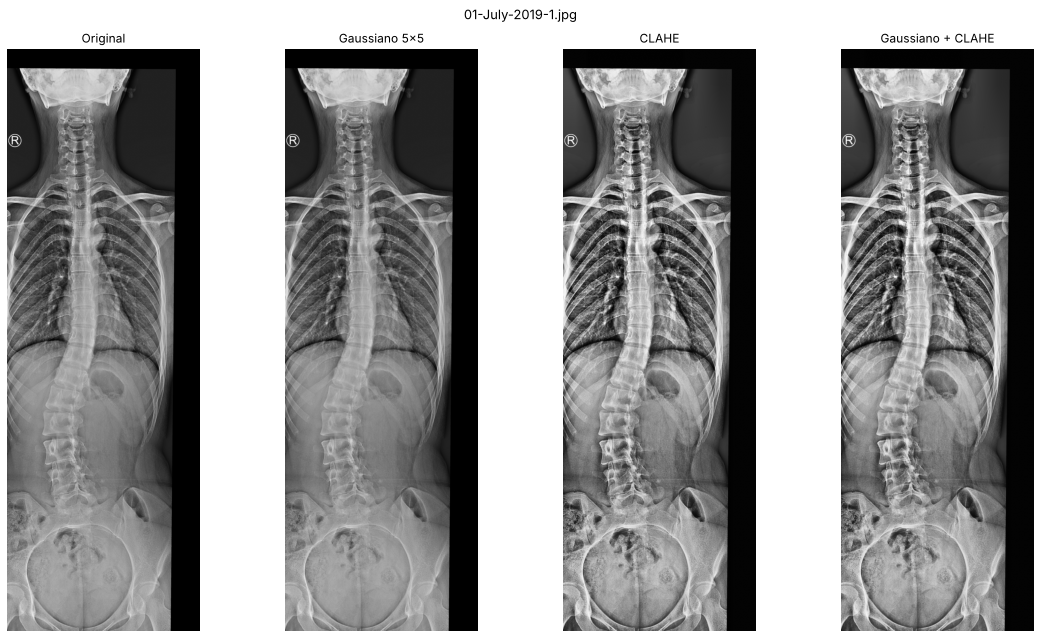

In [6]:
vis.comparar_preprocesamientos(img, ruta.name); plt.show()

**Proyección vertical.** Dentro de una región central se promedia la intensidad de cada columna de píxeles y se suaviza el perfil. Su máximo da una primera estimación de la posición horizontal de la columna. No es una segmentación: otras estructuras brillantes pueden desplazar el máximo, por eso se usa sólo para centrar una ROI amplia.

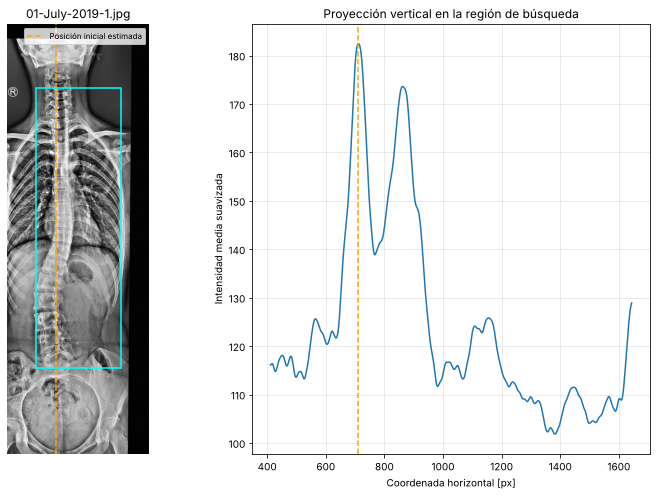

In [7]:
vis.proyeccion_vertical(img, ruta.name); plt.show()

### 3.2 ROI de la columna, matriz ósea y realce

1. **Mediana 9×9** para reducir el ruido granular preservando bordes.
2. **ROI**: centrada en el máximo de la suma de columnas, con un ancho del 45 % de la imagen (para incluir curvas laterales) y entre el 10 % y el 90 % del alto.
3. **Sustracción de fondo**: una apertura con un rectángulo de 8 % × 4 % de la imagen estima el fondo de baja frecuencia (tejidos blandos, iluminación), que se resta para obtener la *matriz ósea*.
4. **CLAHE** (`clipLimit=3.0`) + **Top-Hat** elíptico (¼ del ancho × 1/14 del alto de la ROI), combinados 0,55 / 0,45, forman la *imagen base* usada en las etapas siguientes.

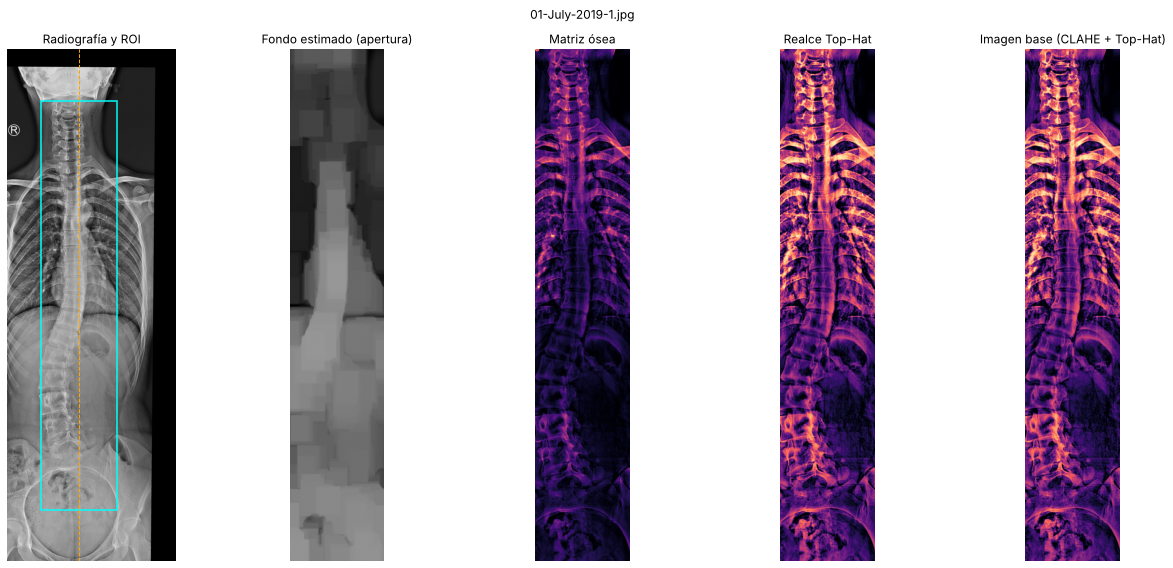

In [8]:
vis.roi_y_realce(r, ruta.name); plt.show()

### 3.3 Niveles vertebrales y eje de la columna

**Niveles.** Se calcula el perfil vertical de intensidad en la banda central de la ROI, se le resta su tendencia (Gaussiano de σ = 3,5 % del alto) y se buscan máximos locales. Como los máximos solos son poco confiables, se impone una **secuencia anatómica de 17 niveles** (T1–L5) cuya separación crece linealmente hasta ×1,7 hacia la región lumbar. Cada nivel se desplaza al máximo más cercano sólo si está dentro de ±20 % de la separación local (líneas continuas); si no, conserva la posición regularizada (líneas discontinuas).

**Eje.** Para cada nivel se busca, en un perfil horizontal local, la posición de mayor intensidad penalizando saltos respecto del nivel anterior. Con esos centros se ajusta un polinomio de grado 4, x = p(y); se descartan los centros con residuo mayor a 2,5·MAD y se vuelve a ajustar.

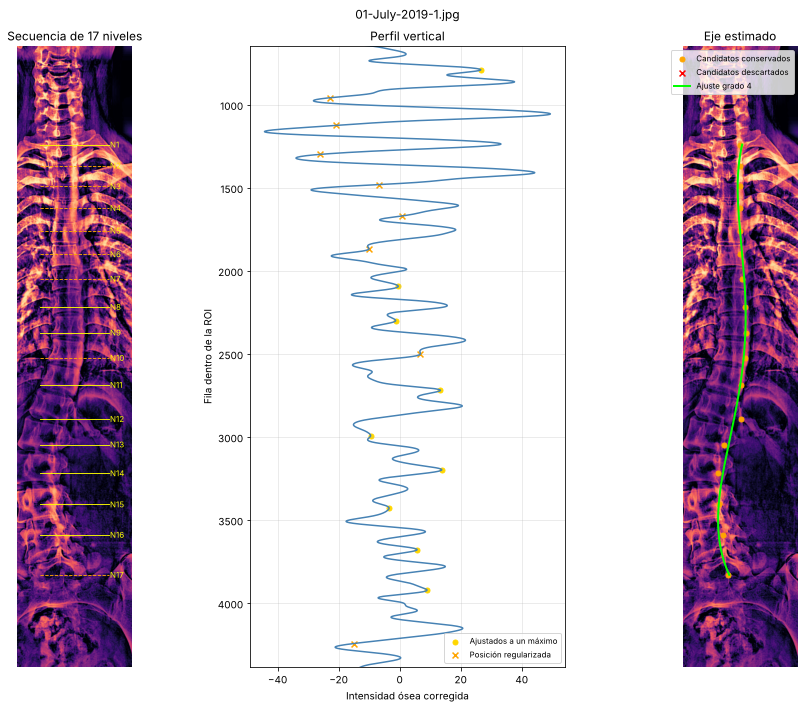

Niveles ajustados a un máximo: 9 de 17


In [9]:
vis.niveles_y_eje(r, ruta.name); plt.show()
print("Niveles ajustados a un máximo:", int(r["ajustado_por_perfil"].sum()), "de 17")

**Cajas vertebrales.** Los mínimos del perfil entre niveles consecutivos se usan como fronteras. Todas las cajas tienen la altura mediana y un ancho del 35 % de la ROI, y se orientan según la pendiente local del eje. Son una restricción espacial para la búsqueda de platillos, no una segmentación.

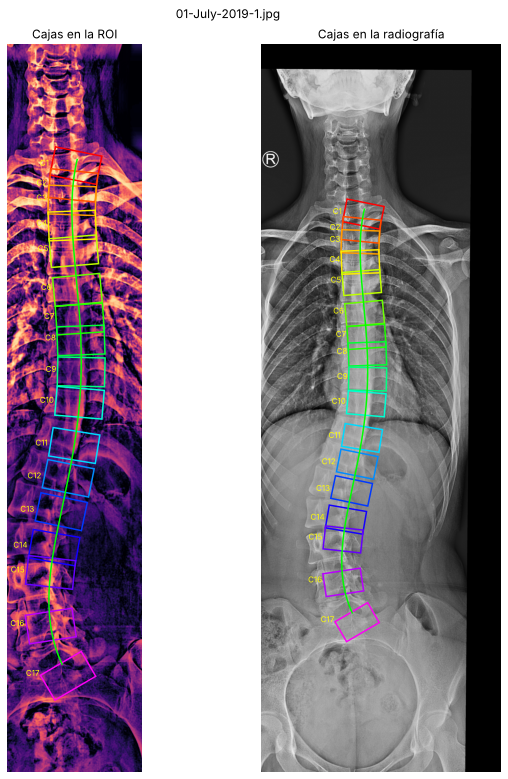

In [10]:
vis.cajas(r, ruta.name); plt.show()

### 3.4 Platillos vertebrales

La transformada de Hough generaba falsas detecciones en las costillas y otros bordes rectos, por lo que se usa un **ajuste restringido de rectas sobre el gradiente** (Sobel tras un Gaussiano 5×5):

- La orientación inicial de cada nivel es perpendicular al eje local, calculada con los niveles vecinos (más estable que la derivada del polinomio en los extremos) y limitada a ±25°.
- Alrededor de la posición esperada de cada platillo (±23 % de la separación desde el centro) se prueban 13 posiciones (±10 %) × 25 inclinaciones (±12°).
- La respuesta de una recta es la media (recortada al percentil 90) de la componente del gradiente perpendicular a ella.
- Puntaje = respuesta normalizada − 0,22·desplazamiento − *w*·giro, con *w* = 0,25 en los 7 niveles superiores (costillas y clavículas) y 0,12 en el resto.

**Control de calidad.** La respuesta de cada platillo se compara con 16 rectas paralelas vecinas (hasta ±18 % de la separación) mediante un puntaje robusto (mediana / MAD). Además se exige una altura relativa del cuerpo de 0,28–0,70 y una diferencia de inclinación ≤ 16° entre sus platillos. Calidad **alta**: confianza ≥ 1 y geometría válida; **media**: confianza ≥ 0; **baja**: el resto (se excluye).
Estos umbrales son valores de control geométrico y estadístico, no criterios clínicos.

,Nivel,Confianza superior,Confianza inferior,Altura relativa,Diferencia angular (°),Calidad
0,C1,6.00,4.71,0.33,11.0,Alta
1,C2,5.58,4.05,0.53,10.0,Alta
2,C3,12.92,0.68,0.43,16.0,Media
3,C4,4.47,0.91,0.41,7.0,Media
4,C5,6.71,4.57,0.48,18.0,Baja
5,C6,5.24,1.12,0.66,11.0,Alta
6,C7,2.19,4.17,0.61,1.0,Alta
7,C8,15.56,3.45,0.54,11.0,Alta
8,C9,7.58,6.50,0.43,12.0,Alta
9,C10,7.46,9.63,0.48,18.0,Baja


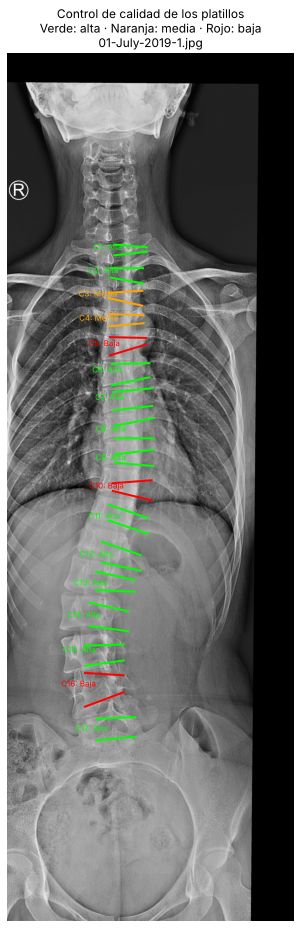

Platillos aceptados: 14 de 17


In [11]:
display(r["tabla_calidad"].round(2))
vis.platillos_calidad(r, ruta.name); plt.show()
print("Platillos aceptados:", int(r["platillos_validos"].sum()), "de 17")

### 3.5 Perfil de inclinaciones y vértebras límite

La inclinación de cada vértebra es la **media circular** de sus dos platillos (las rectas tienen período de 180°). Los niveles rechazados se interpolan, y el perfil se suaviza con **Savitzky-Golay** (ventana 5, orden 2). Se buscan máximos y mínimos con prominencia ≥ max(1,5°; 12 % del rango); dos extremos consecutivos con **inclinaciones de signo opuesto** y un cambio ≥ 5° delimitan una curva. Los límites se trasladan al nivel aceptado más próximo. Ese cambio de 5° sirve sólo para detectar curvas candidatas y no es el umbral diagnóstico de escoliosis.

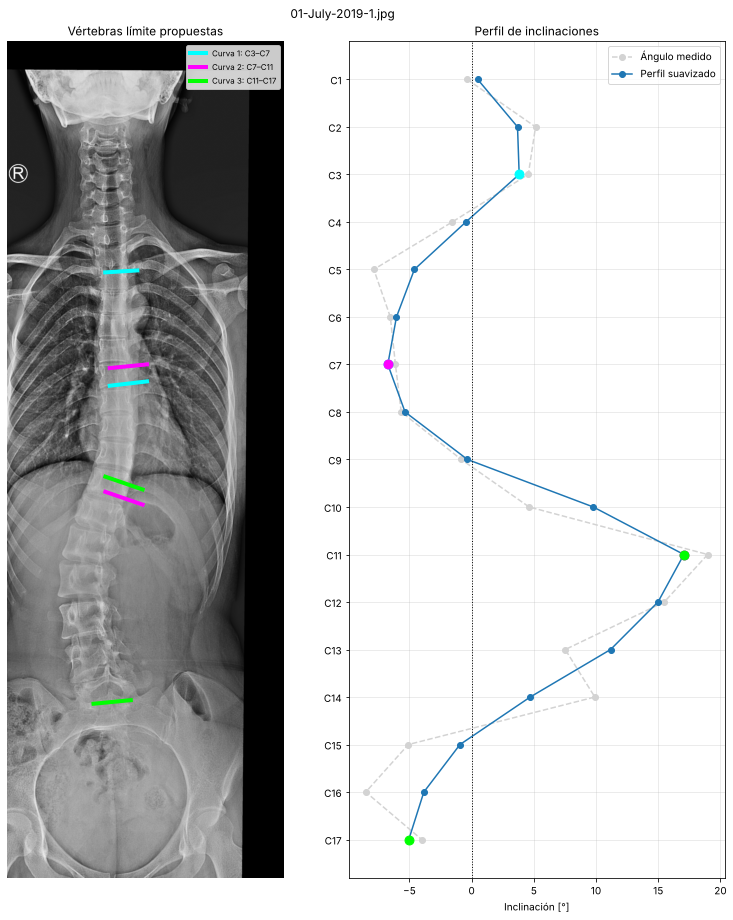

In [12]:
vis.perfil_inclinaciones(r, ruta.name); plt.show()

### 3.6 Ángulo de Cobb y gravedad

Para cada curva se toma el platillo **superior** de la vértebra límite superior y el **inferior** de la vértebra límite inferior:

$$\theta_{Cobb} = \min\left(|\theta_s-\theta_i|,\ 180^\circ-|\theta_s-\theta_i|\right)$$

La curva principal es la de mayor ángulo.

,curva,limite_superior,limite_inferior,angulo_superior,angulo_inferior,cobb,gravedad
0,1,3,7,-3.44,-6.62,3.18,Inferior al umbral de 10°
1,2,7,11,-5.62,18.97,24.60,Leve
2,3,11,17,18.97,-5.51,24.48,Leve


Curva principal: C7–C11 · 24.60° · Leve


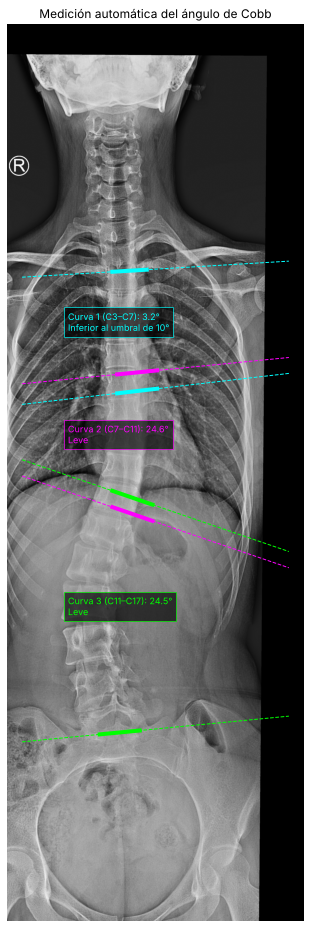

In [13]:
tabla_cobb = pd.DataFrame(r["resultados"])
display(tabla_cobb.round(2))
principal = cp.curva_principal(r["resultados"])
print(f"Curva principal: C{principal['limite_superior']}–C{principal['limite_inferior']} · "
      f"{principal['cobb']:.2f}° · {principal['gravedad']}")
vis.cobb(r); plt.show()

### 3.7 Comparación con la referencia (sólo evaluación)

Recién ahora se leen las anotaciones de esta radiografía. A partir de ellas se calcula el ángulo de cada platillo y se aplica **el mismo criterio de selección de curvas** (sin control de calidad), así los ángulos automáticos y de referencia son comparables.

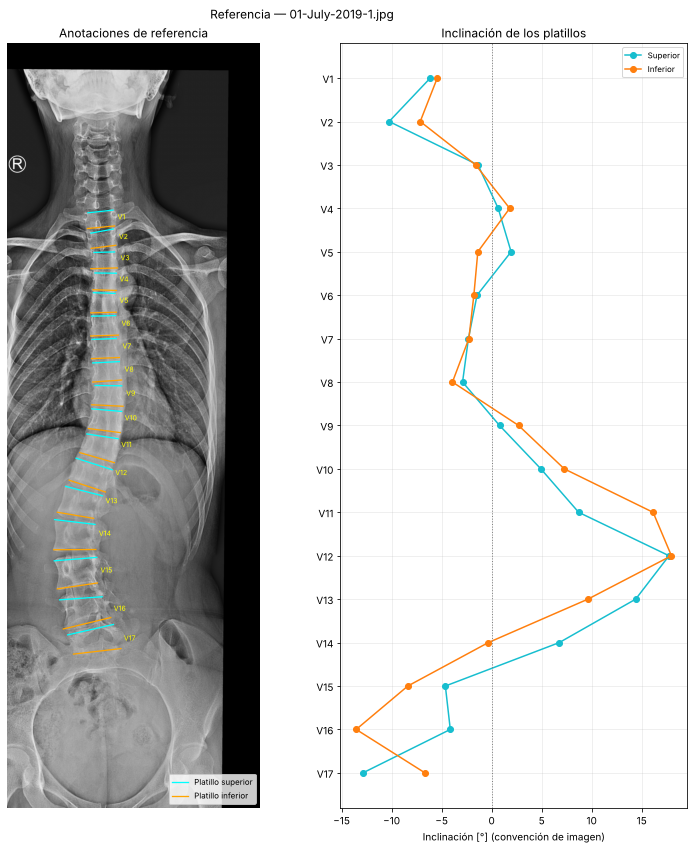

,curva,limite_superior,limite_inferior,angulo_superior,angulo_inferior,cobb,gravedad
0,1,1,4,-6.14,1.80,7.94,Inferior al umbral de 10°
1,2,7,12,-2.32,17.97,20.29,Leve
2,3,12,17,17.74,-6.66,24.40,Leve


In [14]:
ref = cp.obtener_referencia(ruta.name, REF)
vis.referencia(img, ref, titulo=f"Referencia — {ruta.name}"); plt.show()
display(pd.DataFrame(ref["resultados"]).round(2))

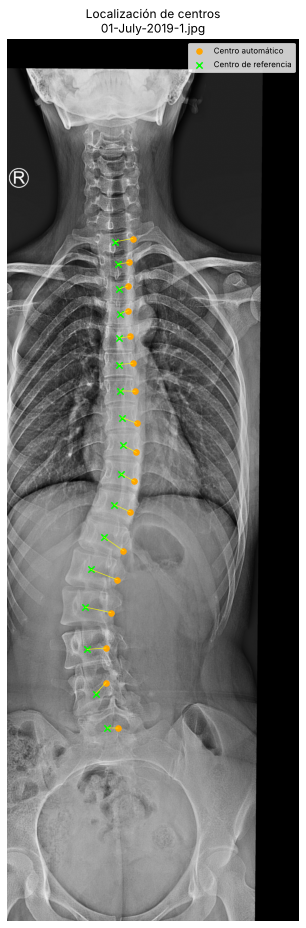

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
Nivel,N1,N2,N3,N4,N5,N6,N7,N8,N9,N10,N11,N12,N13,N14,N15,N16,N17
Error x [px],123.0,78.5,58.8,55.8,80.5,96.6,106.9,102.8,90.3,95.9,115.0,138.9,185.6,179.9,132.8,71.5,75.3
Error y [px],-22.7,-14.3,-20.6,-20.5,-11.1,-8.7,2.6,40.3,51.4,52.7,52.8,97.3,73.1,38.5,-10.3,-78.0,1.1
Error total [px],125.0,79.7,62.3,59.4,81.3,97.0,107.0,110.4,103.9,109.4,126.5,169.6,199.5,184.0,133.2,105.8,75.3


Error medio |x| = 105.2 px · |y| = 35.1 px · en % del alto: 1.82 %


In [15]:
fig, centros_auto, centros_ref = vis.centros_vs_referencia(r, ref, ruta.name)
plt.show()
err = centros_auto - centros_ref
tabla_centros = pd.DataFrame({
    "Nivel": [f"N{i}" for i in range(1, 18)],
    "Error x [px]": err[:, 0], "Error y [px]": err[:, 1],
    "Error total [px]": np.hypot(err[:, 0], err[:, 1])})
display(tabla_centros.round(1).T)
print(f"Error medio |x| = {np.abs(err[:, 0]).mean():.1f} px · "
      f"|y| = {np.abs(err[:, 1]).mean():.1f} px · "
      f"en % del alto: {100 * np.hypot(*err.T).mean() / img.shape[0]:.2f} %")

## 4. Interfaz interactiva

La interfaz permite elegir cualquiera de las 98 radiografías y ver el resultado automático: platillos límite, ángulo de Cobb y gravedad de cada curva. Opcionalmente superpone los platillos límite de la referencia (línea punteada blanca) y muestra la tabla comparativa.

**Uso:** elegir la radiografía en el menú desplegable, marcar o desmarcar *Mostrar referencia* y presionar **Analizar**. El procesamiento tarda unos segundos por imagen.

In [ ]:
import ipywidgets as w

selector = w.Dropdown(options=[(p.name, i) for i, p in enumerate(imagenes)],
                      description="Radiografía:", layout=w.Layout(width="360px"))
con_ref = w.Checkbox(value=True, description="Mostrar referencia")
boton = w.Button(description="Analizar", button_style="primary", icon="search")
salida = w.Output()


def analizar(_=None):
    with salida:
        salida.clear_output(wait=True)
        ruta_i = imagenes[selector.value]
        img_i = cv2.imread(str(ruta_i), cv2.IMREAD_GRAYSCALE)
        res = cp.procesar_radiografia(img_i)
        ref_i = cp.obtener_referencia(ruta_i.name, REF) if con_ref.value else None

        fig, axes = plt.subplots(1, 2, figsize=(12, 10),
                                 gridspec_kw={"width_ratios": [1, 0.9]})
        vis.cobb(res, ax=axes[0], referencia=ref_i,
                 titulo=f"{ruta_i.name}\nautomático (color) · referencia (punteado)")
        axes[1].plot(res["angulos_suavizados"], np.arange(17), "o-",
                     label="Automático (suavizado)")
        if ref_i is not None:
            axes[1].plot(cp.angulo_representativo(ref_i["angulos_superiores"],
                                                  ref_i["angulos_inferiores"]),
                         np.arange(17), "s--", color="gray", label="Referencia")
        axes[1].axvline(0, color="k", ls=":", lw=1)
        axes[1].set_yticks(range(17))
        axes[1].set_yticklabels([f"C{i + 1}" for i in range(17)])
        axes[1].invert_yaxis()
        axes[1].set_xlabel("Inclinación vertebral [°]")
        axes[1].legend(); axes[1].grid(alpha=0.3)
        plt.tight_layout(); plt.show()

        tabla = pd.DataFrame(res["resultados"])[
            ["curva", "limite_superior", "limite_inferior", "cobb", "gravedad"]]
        print("Resultado automático"); display(tabla.round(1))
        if ref_i is not None:
            print("Referencia"); display(pd.DataFrame(ref_i["resultados"])[
                ["curva", "limite_superior", "limite_inferior", "cobb", "gravedad"]].round(1))


boton.on_click(analizar)
display(w.VBox([w.HBox([selector, con_ref, boton]), salida]))

## 5. Evaluación sobre las 98 radiografías

Cada imagen se **procesa primero sin referencia** y luego se compara. Las curvas automáticas y de referencia se emparejan de forma voraz por la superposición (IoU) de sus intervalos de vértebras; sólo las curvas emparejadas aportan al error del ángulo. Las curvas automáticas sin pareja se cuentan como falsas positivas, y las de referencia sin pareja como no detectadas.

Los resultados se informan por separado para 20 radiografías de **calibración** y 78 de **validación**, con una partición reproducible (semilla fija). El procesamiento completo tarda entre 5 y 10 minutos.

In [17]:
imagenes_calibracion = set(cp.separar_calibracion([p.name for p in imagenes], 20, semilla=2026))

filas_resumen, filas_curvas = [], []
for k, ruta_i in enumerate(imagenes, start=1):
    try:
        resumen, filas = cp.evaluar_imagen(ruta_i, REF)
    except Exception as e:
        resumen, filas = {"archivo": ruta_i.name, "estado": f"ERROR: {e}"}, []
    filas_resumen.append(resumen)
    filas_curvas.extend(filas)
    print(f"\r[{k:02d}/98] {ruta_i.name:<24} {resumen['estado']}", end="")

conjunto = lambda n: "Calibración" if n in imagenes_calibracion else "Validación"
tabla_resumen_98 = pd.DataFrame(filas_resumen)
tabla_resultados_98 = pd.DataFrame(filas_curvas)
tabla_resumen_98["conjunto"] = tabla_resumen_98["archivo"].map(conjunto)
tabla_resultados_98["conjunto"] = tabla_resultados_98["archivo"].map(conjunto)
comparaciones = tabla_resultados_98[tabla_resultados_98["estado_curva"] == "Emparejada"].copy()

Path("resultados").mkdir(exist_ok=True)
tabla_resumen_98.to_csv("resultados/resumen_procesamiento_98.csv", index=False)
tabla_resultados_98.to_csv("resultados/resultados_cobb_98.csv", index=False)
print("\nRadiografías procesadas sin error:", (tabla_resumen_98["estado"] == "OK").sum())

[98/98] 01-July-2019-98.jpg      OK
Radiografías procesadas sin error: 98


### 5.1 Métricas

In [18]:
filas = []
for nombre in ["Calibración", "Validación"]:
    datos = comparaciones[comparaciones["conjunto"] == nombre]
    res_c = tabla_resumen_98[tabla_resumen_98["conjunto"] == nombre]
    filas.append({"Conjunto": nombre, "Radiografías": len(res_c),
                  "Curvas referencia": int(res_c["curvas_referencia"].sum()),
                  "Curvas automáticas": int(res_c["curvas_automaticas"].sum()),
                  **cp.metricas(datos)})
filas.append({"Conjunto": "Total", "Radiografías": len(tabla_resumen_98),
              "Curvas referencia": int(tabla_resumen_98["curvas_referencia"].sum()),
              "Curvas automáticas": int(tabla_resumen_98["curvas_automaticas"].sum()),
              **cp.metricas(comparaciones)})
metricas_finales = pd.DataFrame(filas)
display(metricas_finales.round(2))
metricas_finales.to_csv("resultados/metricas_finales.csv", index=False)

,Conjunto,Radiografías,Curvas referencia,Curvas automáticas,Curvas comparadas,MAE Cobb (°),Mediana error (°),Dentro de ±5° (%),Gravedad correcta (%)
0,Calibración,20,44,40,33,9.66,7.27,36.36,57.58
1,Validación,78,166,181,137,10.36,6.89,33.58,45.26
2,Total,98,210,221,170,10.23,7.02,34.12,47.65


**Curva principal por radiografía.** Para cada imagen se compara la curva de mayor ángulo de cada método, sin emparejar. Es la medida más cercana a un uso clínico (un valor de Cobb por estudio).

In [19]:
def principal_por_imagen(df, col_cobb, col_grav):
    d = df.dropna(subset=[col_cobb]).sort_values(col_cobb, ascending=False)
    return d.drop_duplicates("archivo")[["archivo", col_cobb, col_grav]]

auto_p = principal_por_imagen(tabla_resultados_98, "cobb_automatico", "gravedad_automatica")
ref_p = principal_por_imagen(tabla_resultados_98, "cobb_referencia", "gravedad_referencia")
principal = auto_p.merge(ref_p, on="archivo")
principal["conjunto"] = principal["archivo"].map(conjunto)
principal["error"] = (principal["cobb_automatico"] - principal["cobb_referencia"]).abs()
principal["coincide"] = principal["gravedad_automatica"] == principal["gravedad_referencia"]
resumen_principal = principal.groupby("conjunto").agg(
    imagenes=("error", "size"), MAE=("error", "mean"), mediana=("error", "median"),
    dentro_5=("error", lambda e: 100 * e.le(5).mean()),
    gravedad_ok=("coincide", lambda c: 100 * c.mean()))
display(resumen_principal.round(2))
corr = np.corrcoef(principal["cobb_automatico"], principal["cobb_referencia"])[0, 1]
print(f"Correlación de Pearson (curva principal, 98 imágenes): r = {corr:.2f}")
principal.to_csv("resultados/curva_principal_98.csv", index=False)

,imagenes,MAE,mediana,dentro_5,gravedad_ok
conjunto,,,,,
Calibración,20,11.02,8.75,25.00,60.00
Validación,78,11.56,6.85,25.64,44.87


Correlación de Pearson (curva principal, 98 imágenes): r = 0.25


### 5.2 Concordancia y análisis de errores

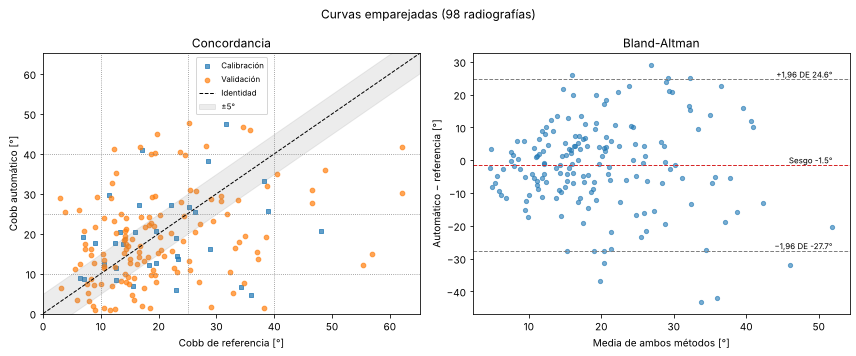

Sesgo medio: -1.51° · límites de acuerdo 95 %: [-27.7°, 24.6°]


In [20]:
vis.dispersion_cobb(comparaciones, "Curvas emparejadas (98 radiografías)"); plt.show()
dif = comparaciones["cobb_automatico"] - comparaciones["cobb_referencia"]
print(f"Sesgo medio: {dif.mean():.2f}° · límites de acuerdo 95 %: "
      f"[{dif.mean() - 1.96 * dif.std():.1f}°, {dif.mean() + 1.96 * dif.std():.1f}°]")

Automática,Inferior al umbral de 10°,Leve,Moderada,Severa
Referencia,,,,
Inferior al umbral de 10°,11,11,4,0
Leve,22,57,12,6
Moderada,7,14,12,5
Severa,0,3,5,1


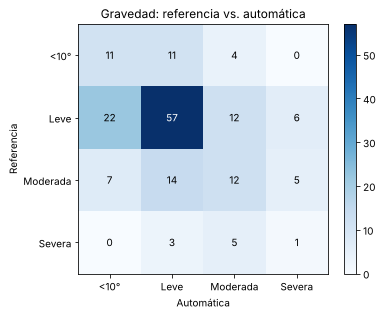

In [21]:
matriz = pd.crosstab(comparaciones["gravedad_referencia"], comparaciones["gravedad_automatica"],
                     rownames=["Referencia"], colnames=["Automática"]).reindex(
    index=cp.ORDEN_GRAVEDAD, columns=cp.ORDEN_GRAVEDAD, fill_value=0)
display(matriz)
vis.matriz_confusion(matriz); plt.show()
matriz.to_csv("resultados/matriz_confusion_98.csv")

In [22]:
# Detección de curvas y localización de centros
det = tabla_resumen_98.assign(
    falsas_positivas=lambda d: (d["curvas_automaticas"] - d["curvas_emparejadas"]).clip(lower=0),
    no_detectadas=lambda d: (d["curvas_referencia"] - d["curvas_emparejadas"]).clip(lower=0))
print("Curvas de referencia:", det["curvas_referencia"].sum(),
      "| emparejadas:", det["curvas_emparejadas"].sum(),
      "| no detectadas:", det["no_detectadas"].sum(),
      "| automáticas sin pareja:", det["falsas_positivas"].sum())
print(f"IoU medio de los límites emparejados: {comparaciones['superposicion_limites'].mean():.2f}")
print(f"Error medio de centros: |x| = {det['error_centro_x_px'].mean():.0f} px, "
      f"|y| = {det['error_centro_y_px'].mean():.0f} px, "
      f"total = {(100 * det['error_centro_px'] / det['alto_px']).mean():.2f} % del alto")

# Error según si los límites coinciden con la referencia
comparaciones["limites_iguales"] = (
    (comparaciones["limite_superior_auto"] == comparaciones["limite_superior_ref"])
    & (comparaciones["limite_inferior_auto"] == comparaciones["limite_inferior_ref"]))
comparaciones["IoU ≥ 0,6"] = comparaciones["superposicion_limites"] >= 0.6
print(f"Límites idénticos a la referencia: {comparaciones['limites_iguales'].sum()} curvas, "
      f"MAE = {comparaciones.loc[comparaciones['limites_iguales'], 'error_absoluto'].mean():.2f}°")
display(comparaciones.groupby("IoU ≥ 0,6")["error_absoluto"].agg(["size", "mean", "median"]).round(2))

# Sesgo según la gravedad de referencia
comparaciones["diferencia"] = comparaciones["cobb_automatico"] - comparaciones["cobb_referencia"]
display(comparaciones.groupby("gravedad_referencia").agg(
    curvas=("diferencia", "size"), sesgo=("diferencia", "mean"),
    MAE=("error_absoluto", "mean")).reindex(cp.ORDEN_GRAVEDAD).round(2))

Curvas de referencia: 210 | emparejadas: 170 | no detectadas: 40 | automáticas sin pareja: 51
IoU medio de los límites emparejados: 0.65
Error medio de centros: |x| = 117 px, |y| = 166 px, total = 4.31 % del alto
Límites idénticos a la referencia: 15 curvas, MAE = 5.61°


,size,mean,median
"IoU ≥ 0,6",,,
False,67,10.75,7.87
True,103,9.89,6.71


,curvas,sesgo,MAE
gravedad_referencia,,,
Inferior al umbral de 10°,26,6.33,8.39
Leve,97,1.35,8.01
Moderada,38,-8.83,13.85
Severa,9,-24.17,24.17


In [23]:
peores = comparaciones.sort_values("error_absoluto", ascending=False).head(10)
display(peores[["archivo", "conjunto", "limite_superior_auto", "limite_inferior_auto",
                "cobb_automatico", "limite_superior_ref", "limite_inferior_ref",
                "cobb_referencia", "error_absoluto"]].round(1))

,archivo,conjunto,limite_superior_auto,limite_inferior_auto,cobb_automatico,limite_superior_ref,limite_inferior_ref,cobb_referencia,error_absoluto
236,01-July-2019-91.jpg,Validación,10.0,13.0,12.2,10.0,14.0,55.3,43.1
71,01-July-2019-35.jpg,Validación,13.0,15.0,15.0,10.0,15.0,56.9,41.9
14,01-July-2019-14.jpg,Validación,13.0,17.0,1.4,12.0,17.0,38.3,36.9
15,01-July-2019-14.jpg,Validación,5.0,13.0,30.1,8.0,12.0,62.1,32.0
75,01-July-2019-36.jpg,Calibración,11.0,14.0,4.8,11.0,16.0,36.0,31.2
233,01-July-2019-9.jpg,Validación,5.0,13.0,41.3,4.0,10.0,12.3,29.0
44,01-July-2019-25.jpg,Validación,13.0,17.0,5.1,10.0,15.0,32.9,27.8
81,01-July-2019-38.jpg,Calibración,5.0,13.0,6.5,6.0,13.0,34.3,27.8
118,01-July-2019-5.jpg,Validación,5.0,11.0,1.6,7.0,14.0,29.1,27.6
35,01-July-2019-22.jpg,Calibración,2.0,9.0,20.8,3.0,11.0,48.0,27.3


### 5.3 Casos ilustrativos

A la izquierda, la radiografía con menor error entre las curvas cuyas vértebras límite coinciden con la referencia; a la derecha, la de mayor error. La referencia se muestra en línea punteada blanca.

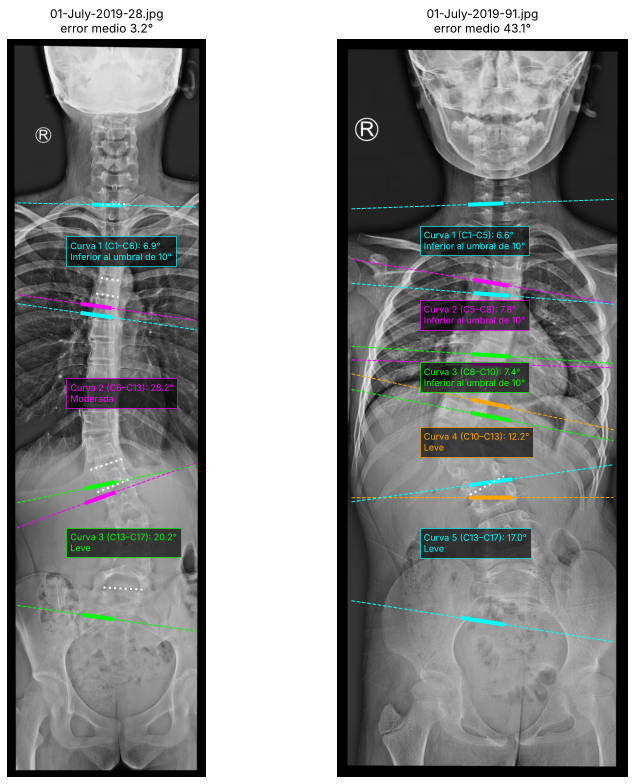

In [24]:
por_imagen = comparaciones.groupby("archivo")["error_absoluto"].mean().sort_values()
buena = (comparaciones[comparaciones["limites_iguales"]]
         .sort_values("error_absoluto")["archivo"].iloc[3])
casos = [buena, por_imagen.index[-1]]
fig, axes = plt.subplots(1, 2, figsize=(12, 11))
for ax, nombre in zip(axes, casos):
    ruta_i = DATA_DIR / nombre if (DATA_DIR / nombre).exists() else next(DATA_DIR.rglob(nombre))
    img_i = cv2.imread(str(ruta_i), cv2.IMREAD_GRAYSCALE)
    vis.cobb(cp.procesar_radiografia(img_i), ax=ax,
             referencia=cp.obtener_referencia(nombre, REF),
             titulo=f"{nombre}\nerror medio {por_imagen[nombre]:.1f}°")
plt.tight_layout(); plt.show()

## 6. Conclusiones

- El pipeline procesa las 98 radiografías sin errores, con técnicas exclusivamente clásicas: filtrado de mediana, apertura y Top-Hat morfológicos, CLAHE, perfiles de intensidad, ajuste polinómico robusto, ajuste restringido de rectas sobre el gradiente y selección de vértebras límite sobre el perfil angular.
- Sobre 170 curvas emparejadas (de 210 de referencia), el error absoluto medio del ángulo de Cobb es ≈ 10° (mediana ≈ 7°) y alrededor de un tercio de las curvas queda dentro de ±5°. Es más del doble que la variabilidad entre observadores reportada para la medición manual (≈ 5–7°), y la concordancia de la gravedad ronda el 48 %.
- El sesgo depende de la magnitud de la curva: se **sobreestiman** las curvas chicas y se **subestiman** las moderadas y, sobre todo, las severas. La búsqueda restringida de platillos (±12° alrededor de una inclinación inicial limitada a ±25°, con penalización de giro) y el suavizado del perfil favorecen inclinaciones moderadas.
- La **elección de las vértebras límite** es determinante: en las curvas cuyos límites coinciden con la referencia el error baja a ≈ 5,6°. Como los 17 niveles se distribuyen entre fracciones fijas del alto de la ROI, en los encuadres que incluyen cráneo o pelvis los niveles se desplazan respecto de T1–L5. A eso se suman los bordes de costillas, clavículas y pelvis, que interfieren con los platillos de los extremos.
- El método no es apto para uso clínico, pero es una **prueba de concepto interpretable**: cada etapa puede inspeccionarse visualmente. Como mejoras se proponen detectar la extensión vertical real de la columna (T1 y L5) antes de distribuir los niveles, segmentar los cuerpos vertebrales (contornos activos o *watershed*), ampliar la búsqueda angular en curvas pronunciadas y calibrar los umbrales en un conjunto de entrenamiento independiente.